# Autoencodeur multimodal et alignement temporel (version 3)

Ce notebook reprend l'expérience de `multimodal_ai_autoencodeur.ipynb` (remplacer la CCA par un autoencodeur multimodal, évalué de la même façon), corrige ses faiblesses (version 2), et ajoute **l'alignement temporel** entre les signaux (sections 8 à 10), en s'appuyant sur Hou et al. (2024), *Emotion Recognition From Multimodal Physiological Signals via Discriminative Correlation Fusion With a Temporal Alignment Mechanism*, IEEE Transactions on Cybernetics.

| Faiblesse du premier essai | Correction dans ce notebook |
| --- | --- |
| 6 participants seulement | Utilise tous les participants téléchargés ; une cellule optionnelle en télécharge d'autres (section 1) |
| 2 signaux seulement (cœur, peau) | Ajoute la **respiration** et la **pupille** (sections 2 et 3) |
| Une seule mesure (balanced accuracy) | Ajoute l'**AUC**, pour comparer avec les autres équipes (section 6) |
| Corrélation cœur–peau inéquitable pour l'autoencodeur | La dimension comparée est choisie sur les participants d'apprentissage (section 5) |
| Pas de test statistique entre méthodes | Comparaison participant par participant : nombre de victoires, test de Wilcoxon, intervalle de confiance bootstrap (section 7) |
| On ne sait pas quelle règle de l'autoencodeur aide | Ablation : reconstruction seule, sans traduction, sans ressemblance des codes (sections 4 et 6) |
| Comparaisons sur des essais différents | Toutes les versions sont évaluées sur **exactement les mêmes essais** |
| Tous les signaux regardés dans la même fenêtre, alors qu'ils ne réagissent pas au même moment | **Alignement temporel** : chaque signal peut être décalé de 0 à 6 s ; le décalage est choisi sur les participants d'apprentissage (sections 8 à 10) |
| La CCA ignore les notes d'arousal | **DCCA** (CCA discriminante, qui utilise les notes) et **tDCCA** (DCCA + décalage), comme dans Hou et al. 2024 (section 9) |

**Ce qui ne change pas :** test leave-one-participant-out (la personne testée n'est jamais vue), sonde linéaire (régression logistique) sur l'arousal au-dessus ou en dessous de la médiane du participant, et baselines du notebook d'origine.

**Avant de lancer :** placer ce notebook dans `starting_notebooks/`, activer l'environnement, avoir installé `torch`, et avoir les fichiers `emotion-video` du jour 1 dans `sample/PREPROCESSED/`, plus `sample/labels_train.csv`. Tout tourne sur CPU.

In [1]:
import json
import sys
from itertools import permutations
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
import pyedflib
import torch
from IPython.display import display
from scipy.signal import butter, find_peaks, sosfiltfilt
from scipy.stats import wilcoxon
from sklearn.cross_decomposition import CCA
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from torch import nn

cwd = Path.cwd().resolve()
if (cwd / "starting_notebooks" / "bdf_loader.py").is_file():
    ROOT = cwd
elif cwd.name == "starting_notebooks" and (cwd / "bdf_loader.py").is_file():
    ROOT = cwd.parent
else:
    raise RuntimeError("Lancer le noyau depuis la racine du repo ou depuis starting_notebooks/.")
if str(ROOT / "starting_notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import uV_to_uS

mne.set_log_level("ERROR")
torch.set_num_threads(1)

## 1 · Réglages et participants

`PARTICIPANT_IDS = None` utilise tous les participants téléchargés. Pour en ajouter, mettre `DOWNLOAD_N` à un nombre (par exemple 25) et lancer la cellule : elle choisit au hasard, avec une graine fixe, des participants qui ont au moins 20 notes d'arousal au jour 1, en excluant les participants de test et ceux déjà présents. Environ 220 Mo par participant. Remettre ensuite `DOWNLOAD_N = 0`.

In [2]:
DATA_ROOT = ROOT / "sample"
BDF_ROOT = DATA_ROOT / "PREPROCESSED"
TRIAL_S = 10.0          # fenêtre analysée après le début de la vidéo (s)
BASELINE_S = 2.0        # référence avant la vidéo (s)
MIN_TRIALS = 10         # bons essais minimum par participant
LAGS_S = (0, 1, 2, 3, 4, 5, 6)  # décalages testés pour l'alignement temporel (s)
PARTICIPANT_IDS = None  # None : tous les participants téléchargés
USE_CACHE = True        # garde les résumés calculés dans sample/features_cache/ (relances bien plus rapides)
DOWNLOAD_N = 0          # >0 : télécharge ce nombre de participants en plus (via download_participants.py)
DOWNLOAD_SEED = 42

labels_path = DATA_ROOT / "labels_train.csv"
if not labels_path.is_file():
    raise FileNotFoundError(f"Télécharger labels_train.csv dans {DATA_ROOT}.")
labels = pd.read_csv(labels_path, na_values=["TESTSUBJECT"], usecols=[
    "cohort", "participant_id", "day", "start_marker", "rating_arousal"])
labels["participant_id"] = labels["participant_id"].astype(str).str.strip()
labels["day"] = pd.to_numeric(labels["day"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
labels["start_marker"] = pd.to_numeric(labels["start_marker"], errors="coerce")
labels["rating_arousal"] = pd.to_numeric(labels["rating_arousal"], errors="coerce")
labels = labels.dropna(subset=["day", "start_marker"])
labels[["day", "start_marker"]] = labels[["day", "start_marker"]].astype(int)
keys = ["participant_id", "day", "start_marker"]
if labels.duplicated(keys).any():
    raise ValueError("Marqueurs ambigus dans labels_train.csv.")


def downloaded_ids():
    found = BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf")
    return {path.parent.name for path in found}


if DOWNLOAD_N > 0:
    # Même téléchargement que download_participants.py (à la racine du repo), fichier par fichier, peu de mémoire.
    import subprocess
    script = ROOT / "download_participants.py"
    if not script.is_file():
        raise FileNotFoundError(f"Mettre download_participants.py dans {ROOT}.")
    subprocess.run([sys.executable, str(script), "--n", str(DOWNLOAD_N), "--seed", str(DOWNLOAD_SEED),
                    "--data-root", str(DATA_ROOT)], check=True, cwd=ROOT)

available_bdfs = sorted(BDF_ROOT.glob("P*/P*_day-1_task-emotion-video_multimodal.bdf"))
if PARTICIPANT_IDS is not None:
    by_id = {bdf.parent.name: bdf for bdf in available_bdfs}
    missing = sorted(set(PARTICIPANT_IDS) - set(by_id))
    if missing:
        raise FileNotFoundError(f"Fichiers manquants : {missing}")
    available_bdfs = [by_id[p] for p in PARTICIPANT_IDS]
bdfs = available_bdfs
if not bdfs:
    raise FileNotFoundError(f"Aucun fichier emotion-video du jour 1 dans {BDF_ROOT}.")

marker_key = pd.read_csv(ROOT / "starting_notebooks" / "markers.csv")
video_key = marker_key.loc[marker_key["Start Marker"] >= 10100].set_index("Start Marker")
end_marker = video_key["End Marker"].to_dict()

selected = [bdf.parent.name for bdf in bdfs]
cohorts = labels.loc[labels.participant_id.isin(selected)].groupby("participant_id").cohort.first()
print(f"{len(bdfs)} enregistrements sélectionnés : {', '.join(selected)}")
print("Participants par cohorte :", cohorts.value_counts().sort_index().to_dict())

26 enregistrements sélectionnés : P001, P017, P020, P026, P086, P090, P097, P124, P126, P128, P129, P131, P137, P138, P174, P186, P187, P189, P194, P201, P217, P219, P308, P310, P367, P459
Participants par cohorte : {1: 14, 2: 8, 3: 2, 4: 1, 5: 1}


## 2 · Lire les signaux et calculer les résumés

On lit seulement les canaux utiles, pour économiser la mémoire : cœur (`ECG`), peau (`GSR`), respiration (`Resp`) à 1 000 Hz, et pupille (`pupildiameter_le`, `pupildiameter_ri`) à environ 166 Hz. Les mesures de pupille sont placées sur l'horloge commune avec la même règle que `bdf_loader.py` (fréquence effective et décalage de départ du `.record_map`).

| Signal | Résumés (3 par signal) | Contrôle qualité |
| --- | --- | --- |
| Cœur | Fréquence médiane, variabilité des battements, changement entre la 2e et la 1re moitié (identiques au notebook d'origine) | Au moins 6 battements réalistes |
| Peau | Hausse moyenne après 2 s, hausse maximale, pente, par rapport aux 2 s d'avant (identiques au notebook d'origine) | Ni cassée, ni plate, ni bloquée aux bords |
| Respiration | Rythme (cycles par minute), amplitude (écart-type), changement de niveau par rapport aux 2 s d'avant | Au moins 2 cycles détectés, signal non plat |
| Pupille | Dilatation moyenne, dilatation maximale, pente, par rapport aux 2 s d'avant | Au moins 60 % de mesures valides (hors clignements) avant et pendant la vidéo |

La respiration est en unités arbitraires : seule sa variation compte, et la standardisation par participant (section 4) la rend comparable. La pupille dépend aussi de la luminosité des vidéos, qu'on ne connaît pas.

**Cache.** Les résumés de chaque participant sont enregistrés dans `sample/features_cache/` (ignoré par git avec `sample/`). Aux relances suivantes, ils sont relus en une seconde au lieu de relire le fichier `.bdf`. Changer `TRIAL_S`, `BASELINE_S` ou `LAGS_S` recalcule automatiquement ; mettre `USE_CACHE = False` force un nouveau calcul.

**Fenêtres décalées (pour l'alignement temporel).** Les mêmes résumés sont aussi calculés dans des fenêtres de 10 s qui commencent `τ` secondes après le début de la vidéo, pour chaque `τ` de `LAGS_S`. La référence (les 2 s avant la vidéo) ne bouge pas : seule la fenêtre de réponse glisse. Avec `τ = 0`, on retrouve exactement les résumés habituels. Les colonnes décalées s'appellent par exemple `gsr_mean_delta@3` (fenêtre de 3 à 13 s).

In [3]:
MODALITY_COLS = {
    "ECG": ["ecg_hr", "ecg_rr_sd", "ecg_hr_change"],
    "GSR": ["gsr_mean_delta", "gsr_max_delta", "gsr_slope"],
    "RESP": ["resp_rate", "resp_amp", "resp_level_delta"],
    "PUPIL": ["pup_mean_delta", "pup_max_delta", "pup_slope"],
}
PUPIL_VALID_MM = (1.5, 9.0)   # diamètres plausibles (mm) ; le reste = clignement ou perte
PUPIL_GRID_HZ = 50            # grille de rééchantillonnage de la pupille


def read_signals(bdf):
    # Lit cœur, peau, respiration (1 kHz) et pupille (temps et valeurs) d'un enregistrement.
    record_map = json.loads(bdf.with_suffix(".record_map").read_text(encoding="utf-8"))
    groups = [spec for stream in record_map["stream_map"].values() for spec in stream.values()]
    with pyedflib.EdfReader(str(bdf)) as reader:
        names = reader.getSignalLabels()
        for needed in ["ECG", "GSR", "Resp", "pupildiameter_le", "pupildiameter_ri"]:
            if needed not in names:
                raise ValueError(f"Canal {needed} absent de {bdf.name}.")
        ecg_id, gsr_id, resp_id = names.index("ECG"), names.index("GSR"), names.index("Resp")
        fs = reader.getSampleFrequency(ecg_id)
        n_samples = reader.getNSamples()
        total = record_map.get("TotalSamples")
        n_master = int(min(n_samples[ecg_id], total)) if isinstance(total, int) and total > 0 else int(n_samples[ecg_id])
        ecg = reader.readSignal(ecg_id, 0, n_master)
        gsr_uV = reader.readSignal(gsr_id, 0, n_master)
        resp = reader.readSignal(resp_id, 0, n_master)

        # Pupille : même alignement que bdf_loader.load_bdf.
        gaze = [g for g in groups if g.get("correction", {}).get("RecordType", "").lower() == "oculometry"][0]
        correction = gaze["correction"]
        gaze_rate = float(correction.get("EffectiveSamplingFrequency", correction.get("SamplingFrequency")))
        onset = float(correction.get("OnsetSeconds", 0.0))
        native_count = round(n_master * gaze_rate / fs)
        onset_idx = min(max(round(onset * fs), 0), n_master - 1)
        filler = round(onset * gaze_rate)
        rows = np.round(np.linspace(onset_idx, n_master - 1, native_count - filler)).astype(int)
        eyes = []
        for name in ["pupildiameter_le", "pupildiameter_ri"]:
            idx = names.index(name)
            packed = reader.readSignal(idx, 0, min(native_count, int(n_samples[idx])))
            packed = np.pad(packed, (0, native_count - len(packed)), constant_values=np.nan)[filler:]
            packed[(packed < PUPIL_VALID_MM[0]) | (packed > PUPIL_VALID_MM[1])] = np.nan
            eyes.append(packed)
    with np.errstate(all="ignore"):
        pupil = np.nanmean(np.vstack(eyes), axis=0)
    return {"fs": fs, "ecg": ecg, "gsr_uV": gsr_uV, "gsr_uS": uV_to_uS(gsr_uV), "resp": resp,
            "pupil_t": rows / fs, "pupil": pupil, "duration_s": n_master / fs}


def video_intervals(bdf):
    # Associe chaque début de vidéo à son marqueur de fin (identique au notebook d'origine).
    raw = mne.io.read_raw_bdf(bdf, preload=False, verbose="ERROR")
    events = pd.DataFrame({"time": raw.annotations.onset - raw.first_time,
                           "code": pd.to_numeric(raw.annotations.description, errors="coerce")}
                          ).dropna().reset_index(drop=True)
    raw.close()
    pairs = []
    for i in range(len(events) - 1):
        start, end = events.iloc[i], events.iloc[i + 1]
        marker = int(start.code)
        if marker in end_marker and end.code == end_marker[marker] and end.time > start.time:
            pairs.append((float(start.time), float(end.time), marker))
    return pairs

In [4]:
def detect_beats(ecg, fs):
    sos = butter(2, (5, 20), btype="bandpass", fs=fs, output="sos")
    width = max(1, round(0.08 * fs))
    envelope = np.convolve(np.abs(sosfiltfilt(sos, ecg)), np.ones(width) / width, mode="same")
    peaks, _ = find_peaks(envelope, distance=round(0.4 * fs), prominence=np.std(envelope))
    return peaks


def ecg_features(ecg, fs):
    peaks = detect_beats(ecg, fs)
    rr = np.diff(peaks) / fs
    plausible = (rr >= 0.4) & (rr <= 1.5)
    hr, beat_s = 60 / rr[plausible], peaks[1:][plausible] / fs
    late = beat_s >= TRIAL_S / 2
    if plausible.sum() < 6 or late.all() or not late.any():
        return None
    return {"ecg_hr": np.median(hr), "ecg_rr_sd": 1000 * np.std(rr[plausible]),
            "ecg_hr_change": hr[late].mean() - hr[~late].mean()}


def gsr_features(gsr, fs, lag=0.0):
    # gsr : de -BASELINE_S à +lag+TRIAL_S. Référence avant la vidéo, réponse dans la fenêtre décalée de lag.
    n_base = round(BASELINE_S * fs)
    response = gsr[n_base + round(lag * fs):] - gsr[:n_base].mean()
    seconds = np.arange(len(response)) / fs
    return {"gsr_mean_delta": response[seconds >= 2].mean(), "gsr_max_delta": response.max(),
            "gsr_slope": np.polyfit(seconds[::20], response[::20], 1)[0]}


def gsr_ok(gsr_uS, gsr_raw_window, floor, ceiling):
    if not np.isfinite(gsr_uS).all():
        return "GSR non-finite"
    if np.mean(np.diff(gsr_uS) == 0) > 0.5 or np.mean((gsr_raw_window <= floor) | (gsr_raw_window >= ceiling)) > 0.01:
        return "GSR flat or clipped"
    return None


def resp_features(resp, fs, lag=0.0):
    # resp : de -BASELINE_S à +lag+TRIAL_S. Rythme, amplitude et changement de niveau.
    if not np.isfinite(resp).all() or np.std(resp) == 0:
        return None
    sos = butter(2, (0.1, 1.0), btype="bandpass", fs=fs, output="sos")
    n_base = round(BASELINE_S * fs)
    start = n_base + round(lag * fs)
    window = sosfiltfilt(sos, resp)[start:]
    peaks, _ = find_peaks(window, distance=round(1.5 * fs), prominence=0.5 * np.std(window))
    if len(peaks) < 2:
        return None
    return {"resp_rate": 60 / np.median(np.diff(peaks) / fs),
            "resp_amp": np.std(window),
            "resp_level_delta": resp[start:].mean() - resp[:n_base].mean()}


def pupil_features(times, values, start_s, lag=0.0):
    # Référence de -BASELINE_S à 0, réponse de lag à lag+TRIAL_S, rééchantillonnées à PUPIL_GRID_HZ.
    lo, hi = np.searchsorted(times, [start_s - BASELINE_S - 0.5, start_s + lag + TRIAL_S + 0.5])
    t, v = times[lo:hi], values[lo:hi]
    ok = np.isfinite(v)
    base_grid = start_s + np.arange(-BASELINE_S, 0, 1 / PUPIL_GRID_HZ)
    grid = np.concatenate([base_grid, start_s + lag + np.arange(0, TRIAL_S, 1 / PUPIL_GRID_HZ)])
    base = np.arange(len(grid)) < len(base_grid)
    during = ~base
    # Part de mesures valides : un point de grille compte s'il a une vraie mesure à moins de 20 ms.
    if ok.sum() < 10:
        return None
    nearest = np.abs(t[ok][np.clip(np.searchsorted(t[ok], grid), 0, ok.sum() - 1)] - grid) < 0.02
    if nearest[base].mean() < 0.6 or nearest[during].mean() < 0.6:
        return None
    curve = np.interp(grid, t[ok], v[ok])
    response = curve[during] - curve[base].mean()
    seconds = grid[during] - (start_s + lag)
    return {"pup_mean_delta": response[seconds >= 0.5].mean(), "pup_max_delta": response.max(),
            "pup_slope": np.polyfit(seconds, response, 1)[0]}


def lag_cols(modality, lag):
    # Noms des colonnes d'un signal pour un décalage donné (sans suffixe pour lag = 0).
    return [c if lag == 0 else f"{c}@{lag}" for c in MODALITY_COLS[modality]]


def window_features(sig, start_s, lag, floor, ceiling):
    # Les 12 résumés dans la fenêtre [start+lag, start+lag+TRIAL_S], référence [start-BASELINE_S, start].
    fs = sig["fs"]
    first, onset = round((start_s - BASELINE_S) * fs), round((start_s + lag) * fs)
    last = round((start_s + lag + TRIAL_S) * fs)
    status, feats = {}, {}

    f = ecg_features(sig["ecg"][onset:onset + round(TRIAL_S * fs)], fs)
    status["ECG"] = "kept" if f else "too few ECG beats"
    feats.update(f or {})

    problem = gsr_ok(sig["gsr_uS"][first:last], sig["gsr_uV"][first:last], floor, ceiling)
    status["GSR"] = problem or "kept"
    if not problem:
        feats.update(gsr_features(sig["gsr_uS"][first:last], fs, lag))

    f = resp_features(sig["resp"][first:last], fs, lag)
    status["RESP"] = "kept" if f else "too few breaths or flat"
    feats.update(f or {})

    f = pupil_features(sig["pupil_t"], sig["pupil"], start_s, lag)
    status["PUPIL"] = "kept" if f else "too many invalid samples"
    feats.update(f or {})
    return status, feats

In [5]:
CACHE_DIR = DATA_ROOT / "features_cache"
CACHE_TAG = f"trial{TRIAL_S:g}_base{BASELINE_S:g}_lags{'-'.join(map(str, LAGS_S))}_v3"
rows, log = [], []
for bdf in bdfs:
    participant = bdf.parent.name
    cache_file = CACHE_DIR / f"{participant}_{CACHE_TAG}.pkl"
    if USE_CACHE and cache_file.is_file() and cache_file.stat().st_mtime >= bdf.stat().st_mtime:
        cached = pd.read_pickle(cache_file)
        rows += cached["rows"]
        log += cached["log"]
        print(f"{participant} : résumés repris du cache")
        continue
    n_rows, n_log = len(rows), len(log)
    intervals = video_intervals(bdf)
    sig = read_signals(bdf)
    fs = sig["fs"]
    floor, ceiling = sig["gsr_uV"].min(), sig["gsr_uV"].max()
    for order, (start_s, end_s, marker) in enumerate(intervals):
        entry = {"participant_id": participant, "start_marker": marker}
        if end_s - start_s < TRIAL_S - 0.1:
            log.append({**entry, "ECG": "video shorter than 10 s", "GSR": "video shorter than 10 s",
                        "RESP": "video shorter than 10 s", "PUPIL": "video shorter than 10 s"})
            continue
        if start_s < BASELINE_S or start_s + TRIAL_S > sig["duration_s"]:
            log.append({**entry, "ECG": "window outside recording", "GSR": "window outside recording",
                        "RESP": "window outside recording", "PUPIL": "window outside recording"})
            continue
        status, feats = window_features(sig, start_s, 0, floor, ceiling)
        for lag in LAGS_S:
            if lag == 0 or start_s + lag + TRIAL_S > sig["duration_s"]:
                continue
            _, shifted = window_features(sig, start_s, lag, floor, ceiling)
            feats.update({f"{name}@{lag}": value for name, value in shifted.items()})

        log.append({**entry, **status})
        rows.append({"participant_id": participant, "day": 1, "start_marker": marker, "trial_order": order, **feats})
    del sig
    if USE_CACHE:
        CACHE_DIR.mkdir(exist_ok=True)
        pd.to_pickle({"rows": rows[n_rows:], "log": log[n_log:]}, cache_file)
    print(f"{participant} : {len(intervals)} vidéos lues")

log = pd.DataFrame(log)
all_cols = [c for cols in MODALITY_COLS.values() for c in cols]
all_lag_cols = [c for lag in LAGS_S if lag for m in MODALITY_COLS for c in lag_cols(m, lag)]
features = pd.DataFrame(rows).reindex(columns=keys + ["trial_order"] + all_cols + all_lag_cols)
trials_all = features.merge(labels.drop(columns="cohort"), on=keys, how="left", validate="one_to_one")
print(f"{len(log)} vidéos, {len(trials_all)} essais avec au moins une décision.")

P001 : résumés repris du cache
P017 : résumés repris du cache
P020 : résumés repris du cache
P026 : résumés repris du cache
P086 : résumés repris du cache
P090 : résumés repris du cache
P097 : résumés repris du cache
P124 : résumés repris du cache
P126 : résumés repris du cache
P128 : résumés repris du cache
P129 : résumés repris du cache
P131 : résumés repris du cache
P137 : résumés repris du cache
P138 : résumés repris du cache
P174 : résumés repris du cache
P186 : résumés repris du cache
P187 : résumés repris du cache
P189 : résumés repris du cache
P194 : résumés repris du cache
P201 : résumés repris du cache
P217 : résumés repris du cache
P219 : résumés repris du cache
P308 : résumés repris du cache
P310 : résumés repris du cache
P367 : résumés repris du cache
P459 : résumés repris du cache
1079 vidéos, 1008 essais avec au moins une décision.


## 3 · Contrôle qualité et choix des essais communs

Pour que **toutes les versions soient comparées sur exactement les mêmes essais**, on garde seulement les essais où **les quatre signaux** sont valides, **pour tous les décalages de `LAGS_S`** (sinon les versions alignées et non alignées ne verraient pas les mêmes vidéos), puis les participants qui en ont au moins `MIN_TRIALS`. Si la pupille ou la respiration font perdre trop d'essais, on peut retirer ce signal de `USED_MODALITIES` (par exemple `["ECG", "GSR", "RESP"]`) et relancer à partir d'ici.

In [6]:
USED_MODALITIES = ["ECG", "GSR", "RESP", "PUPIL"]

print("Essais valides par signal (proportion) :")
display(log[USED_MODALITIES].eq("kept").groupby(log.participant_id).mean().round(2))

used_cols = [c for m in USED_MODALITIES for c in MODALITY_COLS[m]]
used_lag_cols = [c for lag in LAGS_S if lag for m in USED_MODALITIES for c in lag_cols(m, lag)]
complete_0 = trials_all.dropna(subset=used_cols)
complete = complete_0.dropna(subset=used_lag_cols).copy()
print(f"Essais complets sans décalage : {len(complete_0)} ; complets pour tous les décalages : {len(complete)}.")
usable = complete.groupby("participant_id").size()
dropped = {p: int(usable.get(p, 0)) for p in selected if usable.get(p, 0) < MIN_TRIALS}
trials = complete.loc[~complete.participant_id.isin(dropped)].reset_index(drop=True)
retained = sorted(trials.participant_id.unique())
if dropped:
    print("Participants exclus (essais complets) :", dropped)
print(f"Gardés : {len(trials)} essais complets, {len(retained)} participants, "
      f"{trials.rating_arousal.notna().sum()} essais avec une note d'arousal.")
print("Participants retenus par cohorte :", cohorts.reindex(retained).value_counts().sort_index().to_dict())
if len(retained) < 3:
    raise RuntimeError("Il faut au moins 3 participants retenus.")

Essais valides par signal (proportion) :


,ECG,GSR,RESP,PUPIL
participant_id,,,,
P001,0.92,0.92,0.92,0.92
P017,0.94,0.94,0.89,0.94
P020,0.97,0.97,0.83,0.97
P026,0.97,0.00,0.75,0.97
P086,0.92,0.92,0.86,0.92
P090,0.97,0.25,0.78,0.97
P097,0.97,0.97,0.78,0.97
P124,0.97,0.00,0.97,0.97
P126,0.94,0.94,0.75,0.94


Essais complets sans décalage : 755 ; complets pour tous les décalages : 598.
Participants exclus (essais complets) : {'P026': 0, 'P090': 1, 'P124': 0, 'P138': 1, 'P189': 9, 'P367': 8}
Gardés : 579 essais complets, 20 participants, 505 essais avec une note d'arousal.
Participants retenus par cohorte : {1: 10, 2: 7, 3: 2, 4: 1}


## 4 · Standardiser, découper en plis, apprendre les représentations

- **Standardisation par participant** (z-score), comme dans le notebook d'origine.
- **Plis leave-one-participant-out** : à chaque tour, un participant est mis de côté.
- **Baselines** : PCA (2D) sur tous les résumés, et CCA (2D) entre le cœur et la peau, comme dans le notebook d'origine.
- **Autoencodeur multimodal généralisé** : un encodeur et un décodeur par signal, un code commun de 2 nombres (la moyenne des codes), et trois règles : reconstruction, traduction de chaque signal vers chaque autre, et ressemblance des codes.
- **Variantes testées** (ablation) : l'autoencodeur cœur + peau complet, sa version reconstruction seule, sans traduction, sans ressemblance des codes, et l'autoencodeur sur tous les signaux.

Chaque autoencodeur est entraîné 3 fois par pli (3 graines) ; les résultats sont moyennés. Avec 30 participants, compter quelques minutes.

In [7]:
z = trials.groupby("participant_id")[used_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=0)).fillna(0.0)
X = {m: z[MODALITY_COLS[m]].to_numpy() for m in USED_MODALITIES}
# Mêmes résumés dans les fenêtres décalées : XL[signal][décalage], standardisés de la même façon.
z_lag = trials.groupby("participant_id")[used_lag_cols].transform(lambda x: (x - x.mean()) / x.std(ddof=0)).fillna(0.0)
XL = {m: {lag: (X[m] if lag == 0 else z_lag[lag_cols(m, lag)].to_numpy()) for lag in LAGS_S} for m in USED_MODALITIES}
x_all = np.column_stack([X[m] for m in USED_MODALITIES])
groups = trials.participant_id.to_numpy()
folds = list(LeaveOneGroupOut().split(x_all, groups=groups))
assert all(set(groups[tr]).isdisjoint(groups[te]) for tr, te in folds)

LATENT_DIM, HIDDEN, EPOCHS, LR, WEIGHT_DECAY, SEEDS = 2, 8, 200, 1e-2, 1e-3, (0, 1, 2)
AE_VARIANTS = {
    "AE cœur+peau": (["ECG", "GSR"], {"reconstruction": 1, "traduction": 1, "alignement": 1}),
    "AE cœur+peau · reconstruction seule": (["ECG", "GSR"], {"reconstruction": 1, "traduction": 0, "alignement": 0}),
    "AE cœur+peau · sans traduction": (["ECG", "GSR"], {"reconstruction": 1, "traduction": 0, "alignement": 1}),
    "AE cœur+peau · sans ressemblance": (["ECG", "GSR"], {"reconstruction": 1, "traduction": 1, "alignement": 0}),
    "AE tous signaux": (USED_MODALITIES, {"reconstruction": 1, "traduction": 1, "alignement": 1}),
}


def small_mlp(n_in, n_out):
    return nn.Sequential(nn.Linear(n_in, HIDDEN), nn.Tanh(), nn.Linear(HIDDEN, n_out))


class MultimodalAE(nn.Module):
    def __init__(self, sizes):
        super().__init__()
        self.enc = nn.ModuleList([small_mlp(n, LATENT_DIM) for n in sizes])
        self.dec = nn.ModuleList([small_mlp(LATENT_DIM, n) for n in sizes])

    def encode(self, xs):
        codes = [enc(x) for enc, x in zip(self.enc, xs)]
        return codes, torch.stack(codes).mean(0)

    def loss(self, xs, weights):
        mse = nn.functional.mse_loss
        codes, shared = self.encode(xs)
        k = len(xs)
        parts = {"reconstruction": sum(mse(d(shared), x) for d, x in zip(self.dec, xs)) / k,
                 "traduction": (sum(mse(self.dec[j](codes[i]), xs[j]) for i, j in permutations(range(k), 2))
                                / max(1, k * (k - 1))),
                 "alignement": sum(mse(c, shared) for c in codes) / k}
        return sum(weights[n] * v for n, v in parts.items()), parts


def tensors(mods, rows):
    return [torch.as_tensor(X[m][rows], dtype=torch.float32) for m in mods]


def fit_ae(mods, weights, train, seed):
    torch.manual_seed(seed)
    xs = tensors(mods, train)
    model = MultimodalAE([x.shape[1] for x in xs])
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    for _ in range(EPOCHS):
        opt.zero_grad()
        total, _ = model.loss(xs, weights)
        total.backward()
        opt.step()
    return model.eval()


@torch.no_grad()
def ae_codes(model, mods, rows):
    codes, shared = model.encode(tensors(mods, rows))
    return [c.numpy() for c in codes], shared.numpy()


baselines = []
for train, _ in folds:
    pca = PCA(n_components=2).fit(x_all[train])
    cca = CCA(n_components=2, scale=False, max_iter=1000).fit(X["ECG"][train], X["GSR"][train])
    u, v = cca.transform(X["ECG"][train], X["GSR"][train])
    baselines.append({"pca": pca, "cca": cca, "u_sd": u.std(0), "v_sd": v.std(0)})

ae_models = {name: [] for name in AE_VARIANTS}
for fold_number, (train, test) in enumerate(folds, start=1):
    for name, (mods, weights) in AE_VARIANTS.items():
        ae_models[name].append([fit_ae(mods, weights, train, s) for s in SEEDS])
    print(f"pli {fold_number}/{len(folds)} appris (test : {groups[test][0]})")

pli 1/20 appris (test : P001)
pli 2/20 appris (test : P017)
pli 3/20 appris (test : P020)
pli 4/20 appris (test : P086)
pli 5/20 appris (test : P097)
pli 6/20 appris (test : P126)
pli 7/20 appris (test : P128)
pli 8/20 appris (test : P129)
pli 9/20 appris (test : P131)
pli 10/20 appris (test : P137)
pli 11/20 appris (test : P174)
pli 12/20 appris (test : P186)
pli 13/20 appris (test : P187)
pli 14/20 appris (test : P194)
pli 15/20 appris (test : P201)
pli 16/20 appris (test : P217)
pli 17/20 appris (test : P219)
pli 18/20 appris (test : P308)
pli 19/20 appris (test : P310)
pli 20/20 appris (test : P459)


## 5 · Le lien cœur–peau sur les participants jamais vus (comparaison équitable)

Comme dans le notebook d'origine, on corrèle le score du cœur et celui de la peau sur le participant testé, et on compare à 1 000 mélanges des essais (la zone du hasard).

**Correction :** la CCA range ses dimensions de la plus corrélée à la moins corrélée, l'autoencodeur non. Pour l'autoencodeur, on choisit donc, **sur les participants d'apprentissage**, la dimension où le code du cœur et celui de la peau sont le plus corrélés, et on l'oriente pour que cette corrélation soit positive.

In [8]:
N_SHUFFLES = 1000


def correlation(x, y):
    return np.corrcoef(x, y)[0, 1] if np.std(x) > 0 and np.std(y) > 0 else 0.0


def ae_pair_on_test(model, train, test):
    (c_tr, g_tr), _ = ae_codes(model, ["ECG", "GSR"], train)
    r = [correlation(c_tr[:, d], g_tr[:, d]) for d in range(LATENT_DIM)]
    d = int(np.argmax(np.abs(r)))
    sign = 1.0 if r[d] >= 0 else -1.0
    (c_te, g_te), _ = ae_codes(model, ["ECG", "GSR"], test)
    return c_te[:, d], sign * g_te[:, d]


rng = np.random.default_rng(42)
coupling = []
for k, (train, test) in enumerate(folds):
    u, v = baselines[k]["cca"].transform(X["ECG"][test], X["GSR"][test])
    pairs = {"CCA": [(u[:, 0], v[:, 0])],
             "AE cœur+peau": [ae_pair_on_test(m, train, test) for m in ae_models["AE cœur+peau"][k]]}
    for method, pp in pairs.items():
        observed = np.mean([correlation(a, b) for a, b in pp])
        null = np.array([np.mean([correlation(a, rng.permutation(b)) for a, b in pp]) for _ in range(N_SHUFFLES)])
        coupling.append({"participant": groups[test][0], "méthode": method, "r": observed,
                         "hasard 2.5%": np.percentile(null, 2.5), "hasard 97.5%": np.percentile(null, 97.5),
                         "au-dessus du hasard": observed > np.percentile(null, 97.5)})
coupling = pd.DataFrame(coupling)
display(coupling.pivot(index="participant", columns="méthode", values="r").round(3))
print(coupling.groupby("méthode").agg(r_moyen=("r", "mean"),
                                          participants_au_dessus_du_hasard=("au-dessus du hasard", "sum")).round(3))

méthode,AE cœur+peau,CCA
participant,,
P001,0.122,0.003
P017,-0.226,-0.370
P020,-0.305,-0.101
P086,-0.006,-0.019
P097,-0.418,-0.141
P126,-0.133,-0.013
P128,0.127,0.113
P129,-0.185,-0.030
P131,-0.318,0.120


              r_moyen  participants_au_dessus_du_hasard
méthode                                                
AE cœur+peau   -0.085                                 1
CCA            -0.026                                 1


## 6 · La sonde arousal : balanced accuracy et AUC

Pour chaque pli et chaque version, une régression logistique apprend sur les participants d'apprentissage et prédit pour le participant testé si l'arousal est au-dessus de sa médiane. Deux notes :

- **balanced accuracy** : moyenne des bonnes réponses parmi les vrais Oui et parmi les vrais Non ;
- **AUC** : la probabilité qu'une vidéo « Oui » tirée au hasard reçoive un score plus haut qu'une vidéo « Non » ; elle ne dépend pas d'un seuil et permet de comparer avec d'autres équipes.

Pour les deux, **0,50 = hasard**.

balanced accuracy           AUC         \
                                                 mean    std   mean    std   
version                                                                      
Classe majoritaire                              0.500  0.000  0.500  0.000   
ECG seul                                        0.531  0.104  0.549  0.125   
GSR seul                                        0.533  0.075  0.549  0.076   
RESP seul                                       0.563  0.108  0.582  0.118   
PUPIL seul                                      0.492  0.114  0.497  0.154   
Concaténation cœur+peau                         0.554  0.076  0.560  0.108   
Concaténation tous signaux                      0.559  0.082  0.594  0.104   
PCA (2D) tous signaux                           0.538  0.083  0.554  0.111   
CCA cœur+peau (2D)                              0.526  0.088  0.539  0.103   
AE cœur+peau                                    0.552  0.087  0.561  0.110   
AE cœur+peau · reconstruction seule             0.557  0.085  0.549  0.112   
AE cœur+peau · sans traduction                  0.554  0.091  0.554  0.116   
AE cœur+peau · sans ressemblance                0.550  0.088  0.557  0.113   
AE tous signaux                                 0.558  0.060  0.560  0.060   

                                    participants  
                                               n  
version                                           
Classe majoritaire                            20  
ECG seul                                      20  
GSR seul                                      20  
RESP seul                                     20  
PUPIL seul                                    20  
Concaténation cœur+peau                       20  
Concaténation tous signaux                    20  
PCA (2D) tous signaux                         20  
CCA cœur+peau (2D)                            20  
AE cœur+peau                                  20  
AE cœur+peau · reconstruction seule           20  
AE cœur+peau · sans traduction                20  
AE cœur+peau · sans ressemblance              20  
AE tous signaux                               20

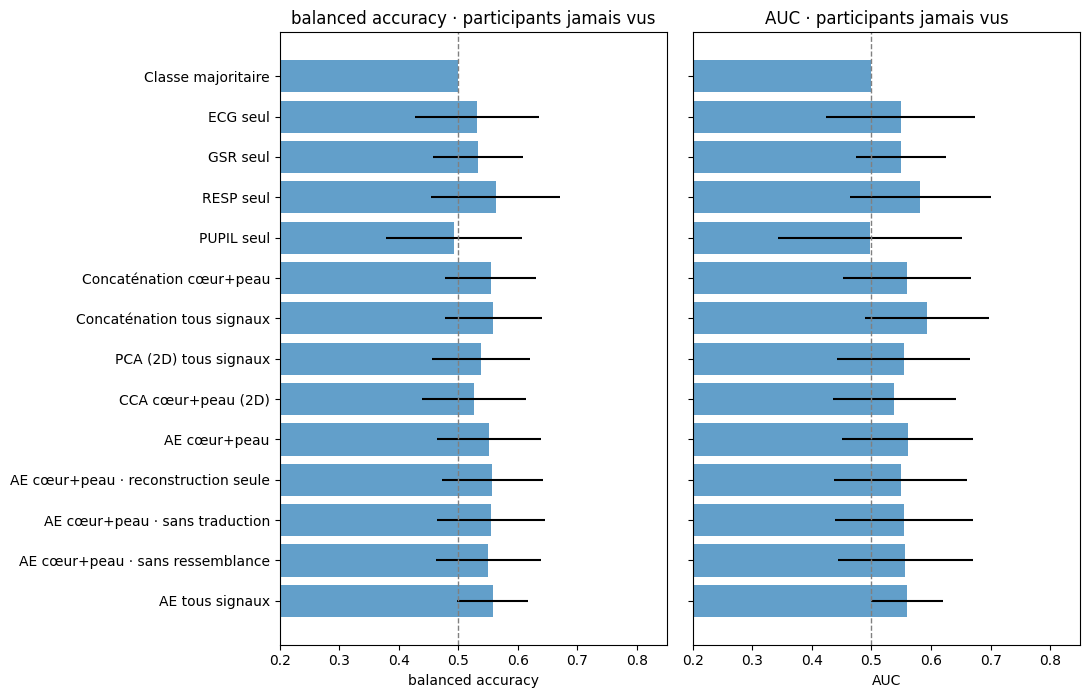

In [9]:
median_rating = trials.groupby("participant_id").rating_arousal.transform("median")
target = trials.rating_arousal.gt(median_rating).astype(float).where(trials.rating_arousal.notna()).to_numpy()
labelled = np.isfinite(target)


def version_features(k, train, rows):
    out = {f"{m} seul": X[m][rows] for m in USED_MODALITIES}
    out["Concaténation cœur+peau"] = np.column_stack([X["ECG"][rows], X["GSR"][rows]])
    out["Concaténation tous signaux"] = x_all[rows]
    out["PCA (2D) tous signaux"] = baselines[k]["pca"].transform(x_all[rows])
    u, v = baselines[k]["cca"].transform(X["ECG"][rows], X["GSR"][rows])
    out["CCA cœur+peau (2D)"] = (u / baselines[k]["u_sd"] + v / baselines[k]["v_sd"]) / 2
    return out


scores = []
for k, (train, test) in enumerate(folds):
    tr, te = train[labelled[train]], test[labelled[test]]
    if len(te) < 5 or len(set(target[te])) < 2 or len(set(target[tr])) < 2:
        continue
    y_tr, y_te = target[tr], target[te]
    participant = groups[test][0]

    dummy = DummyClassifier(strategy="most_frequent").fit(x_all[tr], y_tr)
    scores.append({"participant": participant, "version": "Classe majoritaire",
                   "balanced accuracy": balanced_accuracy_score(y_te, dummy.predict(x_all[te])), "AUC": 0.5})

    def probe(f_tr, f_te):
        model = LogisticRegression(class_weight="balanced", max_iter=1000).fit(f_tr, y_tr)
        return balanced_accuracy_score(y_te, model.predict(f_te)), roc_auc_score(y_te, model.predict_proba(f_te)[:, 1])

    f_tr, f_te = version_features(k, train, tr), version_features(k, train, te)
    for name in f_tr:
        ba, auc = probe(f_tr[name], f_te[name])
        scores.append({"participant": participant, "version": name, "balanced accuracy": ba, "AUC": auc})

    for name, (mods, _) in AE_VARIANTS.items():
        per_seed = [probe(ae_codes(m, mods, tr)[1], ae_codes(m, mods, te)[1]) for m in ae_models[name][k]]
        scores.append({"participant": participant, "version": name,
                       "balanced accuracy": np.mean([s[0] for s in per_seed]), "AUC": np.mean([s[1] for s in per_seed])})

scores = pd.DataFrame(scores)
order = (["Classe majoritaire"] + [f"{m} seul" for m in USED_MODALITIES]
         + ["Concaténation cœur+peau", "Concaténation tous signaux", "PCA (2D) tous signaux",
            "CCA cœur+peau (2D)"] + list(AE_VARIANTS))
summary = scores.groupby("version")[["balanced accuracy", "AUC"]].agg(["mean", "std"]).reindex(order)
summary[("participants", "n")] = scores.groupby("version").size().reindex(order)
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 0.42 * len(order) + 1.2), sharey=True)
for ax, metric in zip(axes, ["balanced accuracy", "AUC"]):
    ax.barh(order, summary[(metric, "mean")], xerr=summary[(metric, "std")], color="tab:blue", alpha=0.7)
    ax.axvline(0.5, color="gray", ls="--", lw=1)
    ax.set(xlabel=metric, xlim=(0.2, 0.85), title=f"{metric} · participants jamais vus")
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## 7 · Comparaisons participant par participant

Chaque participant testé donne une note pour chaque version : on peut donc comparer deux versions **sur les mêmes personnes**. Pour chaque comparaison :

- **victoires** : sur combien de participants la version A fait mieux que B ;
- **différence moyenne** et son **intervalle de confiance à 95 %** (bootstrap sur les participants) : si l'intervalle contient 0, on ne peut pas conclure ;
- **p (Wilcoxon)** : test des rangs signés, adapté aux petits échantillons ; sous 0,05, la différence est considérée comme sérieuse.

Avec autant de comparaisons, une valeur p un peu sous 0,05 peut apparaître par hasard : les retenir comme des pistes, pas comme des preuves.

In [10]:
METRICS = ["AUC", "balanced accuracy"]   # mesure principale d'abord
best_single = summary[("AUC", "mean")].reindex([f"{m} seul" for m in USED_MODALITIES]).idxmax()
COMPARISONS = [
    ("AE cœur+peau", "CCA cœur+peau (2D)"),
    ("AE cœur+peau", "Concaténation cœur+peau"),
    ("AE tous signaux", "AE cœur+peau"),
    ("Concaténation tous signaux", best_single),
    ("AE tous signaux", best_single),
    ("AE cœur+peau · reconstruction seule", "AE cœur+peau"),
    ("AE cœur+peau · sans traduction", "AE cœur+peau"),
    ("AE cœur+peau · sans ressemblance", "AE cœur+peau"),
]
print(f"Meilleur signal seul (AUC) : {best_single}")
for METRIC in METRICS:
    wide = scores.pivot(index="participant", columns="version", values=METRIC)
    rng_boot = np.random.default_rng(0)
    rows_cmp = []
    for a, b in COMPARISONS:
        d = (wide[a] - wide[b]).dropna().to_numpy()
        boot = [rng_boot.choice(d, size=len(d), replace=True).mean() for _ in range(5000)]
        p = wilcoxon(d).pvalue if np.any(d != 0) and len(d) >= 5 else np.nan
        rows_cmp.append({"A": a, "B": b, "victoires de A": f"{int((d > 0).sum())} / {len(d)}",
                         "différence moyenne": d.mean(), "IC 95 % bas": np.percentile(boot, 2.5),
                         "IC 95 % haut": np.percentile(boot, 97.5), "p (Wilcoxon)": p})
    print(f"\nMesure : {METRIC}")
    display(pd.DataFrame(rows_cmp).round(3))

Meilleur signal seul (AUC) : RESP seul

Mesure : AUC


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,AE cœur+peau,CCA cœur+peau (2D),10 / 20,0.022,-0.023,0.067,0.422
1,AE cœur+peau,Concaténation cœur+peau,9 / 20,0.001,-0.039,0.041,0.898
2,AE tous signaux,AE cœur+peau,12 / 20,-0.001,-0.050,0.048,1.000
3,Concaténation tous signaux,RESP seul,14 / 20,0.012,-0.038,0.061,0.596
4,AE tous signaux,RESP seul,10 / 20,-0.022,-0.070,0.026,0.522
5,AE cœur+peau · reconstruction seule,AE cœur+peau,10 / 20,-0.011,-0.032,0.006,0.522
6,AE cœur+peau · sans traduction,AE cœur+peau,9 / 20,-0.006,-0.019,0.006,0.445
7,AE cœur+peau · sans ressemblance,AE cœur+peau,8 / 20,-0.004,-0.017,0.010,0.679



Mesure : balanced accuracy


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,AE cœur+peau,CCA cœur+peau (2D),12 / 20,0.025,-0.024,0.071,0.349
1,AE cœur+peau,Concaténation cœur+peau,8 / 20,-0.003,-0.027,0.024,0.679
2,AE tous signaux,AE cœur+peau,9 / 20,0.006,-0.043,0.057,0.956
3,Concaténation tous signaux,RESP seul,9 / 20,-0.004,-0.048,0.040,0.744
4,AE tous signaux,RESP seul,8 / 20,-0.005,-0.051,0.038,0.927
5,AE cœur+peau · reconstruction seule,AE cœur+peau,11 / 20,0.006,-0.016,0.027,0.469
6,AE cœur+peau · sans traduction,AE cœur+peau,8 / 20,0.003,-0.010,0.016,0.737
7,AE cœur+peau · sans ressemblance,AE cœur+peau,10 / 20,-0.001,-0.015,0.010,0.616


## 8 · L'alignement temporel : l'idée

Jusqu'ici, on regarde **tous les signaux dans la même fenêtre** (0 à 10 s après le début de la vidéo). Or ils ne réagissent pas au même moment :

| Signal | Délai typique de réaction | Source |
| --- | --- | --- |
| Pupille | début vers 0,2 s, réponse en moins de 1 s | Korn & Bach 2016 |
| Cœur | ralentissement vers 1 s, accélérations vers 5 à 7 s | Paulus et al. 2016 |
| Peau (conductance) | pic vers 3 s après l'événement | Bach et al. 2010 |

Hou et al. (2024) montrent le même problème entre le cerveau et le cœur, et proposent la **tDCCA** :

- **D (discriminante)** : au lieu de corréler cœur et peau essai par essai, on corrèle **les moyennes de chaque classe** (arousal haut / bas). La direction trouvée est donc celle où les deux signaux « racontent la même chose sur l'émotion ».
- **t (temporelle)** : on fait glisser la fenêtre d'un signal de `τ` secondes, et on garde le `τ` qui donne le meilleur lien.

**Ce que ce notebook teste :**

1. **La famille CCA** (section 9) : CCA, DCCA, tCCA, tDCCA entre le cœur (fenêtre fixe, la référence) et la peau (fenêtre décalée).
2. **L'autoencodeur aligné** (section 9) : l'autoencodeur cœur + peau entraîné pour chaque décalage de la peau ; on garde le décalage qu'il **traduit le mieux** (perte de traduction la plus basse). C'est l'idée « l'alignement choisi par la traduction ».
3. **Un décalage par signal** (section 9) : pour chaque signal, le décalage qui prédit le mieux l'arousal, puis la concaténation et l'autoencodeur de tous les signaux, chacun à son décalage.
4. **Les décalages choisis** (section 10) : quel délai ressort pour chaque signal ? C'est la question de la latence (hypothèse H1).

**Règle anti-triche :** tous les décalages sont choisis **uniquement sur les participants d'apprentissage**, à l'intérieur de chaque pli. Le participant testé ne sert jamais à choisir `τ`. Pour l'optimisation, l'article utilise une méthode bayésienne ; avec un seul nombre à choisir et 7 valeurs, on les essaie simplement toutes.

**Règle de prudence (`LAG_TOL`) :** quand plusieurs décalages sont presque à égalité, retirer un participant fait mécaniquement baisser le score du décalage où ce participant était le meilleur. Le choix part alors souvent *contre* la personne testée. On garde donc le **plus petit décalage** sauf si un décalage plus grand fait mieux d'au moins `LAG_TOL` (0,01). Un décalage n'est choisi que s'il apporte un gain net.

In [11]:
REF, MOVED = "ECG", "GSR"   # le cœur sert de référence ; on fait glisser la fenêtre de la peau
REG = 1e-3                  # petite régularisation des variances, pour la stabilité
LAG_TOL = 0.01              # un décalage plus grand n'est retenu que s'il fait mieux d'au moins cette marge


def pick_lag(score_by_lag, tol=LAG_TOL):
    # Plus petit décalage dont le score est à moins de tol du meilleur (score : plus grand = mieux).
    best = max(score_by_lag.values())
    return min(lag for lag, s in score_by_lag.items() if s >= best - tol)


def inv_sqrt(s):
    w, v = np.linalg.eigh(s)
    return v @ np.diag(1 / np.sqrt(np.clip(w, 1e-12, None))) @ v.T


def fit_cca_family(x, y, y_class=None, n_components=2):
    # CCA si y_class est None ; DCCA sinon (Hou et al. 2024, équations 11 à 14).
    mx, my = x.mean(0), y.mean(0)
    xc, yc = x - mx, y - my
    n = len(x)
    sxx = xc.T @ xc / n + REG * np.eye(x.shape[1])
    syy = yc.T @ yc / n + REG * np.eye(y.shape[1])
    if y_class is None:
        cross = xc.T @ yc / n                          # covariance cœur-peau, essai par essai
    else:                                              # X A Yᵀ : seules les paires d'une même classe comptent
        cross = sum(np.outer(xc[y_class == c].sum(0), yc[y_class == c].sum(0))
                    for c in np.unique(y_class)) / n
    kx, ky = inv_sqrt(sxx), inv_sqrt(syy)
    u, s, vt = np.linalg.svd(kx @ cross @ ky)
    return {"mx": mx, "my": my, "wx": kx @ u[:, :n_components], "wy": ky @ vt.T[:, :n_components],
            "lambda": s[0]}                            # lambda : valeur du lien pour la 1re dimension


def cca_transform(model, x, y):
    return (x - model["mx"]) @ model["wx"], (y - model["my"]) @ model["wy"]


def fit_ae_arrays(arrays, weights, rows, seed):
    # Même autoencodeur que la section 4, sur des tableaux donnés ; renvoie aussi la perte de traduction finale.
    torch.manual_seed(seed)
    xs = [torch.as_tensor(a[rows], dtype=torch.float32) for a in arrays]
    model = MultimodalAE([x.shape[1] for x in xs])
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    for _ in range(EPOCHS):
        opt.zero_grad()
        total, _ = model.loss(xs, weights)
        total.backward()
        opt.step()
    with torch.no_grad():
        _, parts = model.loss(xs, weights)
    return model.eval(), float(parts["traduction"])


@torch.no_grad()
def ae_shared(model, arrays, rows):
    return model.encode([torch.as_tensor(a[rows], dtype=torch.float32) for a in arrays])[1].numpy()


def probe(f_tr, f_te, y_tr, y_te):
    model = LogisticRegression(class_weight="balanced", max_iter=1000).fit(f_tr, y_tr)
    return balanced_accuracy_score(y_te, model.predict(f_te)), roc_auc_score(y_te, model.predict_proba(f_te)[:, 1])


def inner_auc(features, rows):
    # AUC en validation croisée interne : 5 groupes de participants d'apprentissage, le test n'y est jamais.
    rows = rows[labelled[rows]]
    g, y = groups[rows], target[rows]
    aucs = []
    for a, b in GroupKFold(n_splits=min(5, len(np.unique(g)))).split(rows, y, g):
        if len(set(y[a])) < 2 or len(set(y[b])) < 2:
            continue
        model = LogisticRegression(class_weight="balanced", max_iter=1000).fit(features[rows[a]], y[a])
        aucs.append(roc_auc_score(y[b], model.predict_proba(features[rows[b]])[:, 1]))
    return np.mean(aucs) if aucs else 0.5

## 9 · Apprendre les versions alignées

Pour chaque pli, sur les participants d'apprentissage seulement :

- **CCA / DCCA** : décalage 0. **tCCA / tDCCA** : on essaie chaque décalage de la peau et on garde celui qui donne le plus grand lien `λ`.
- **AE cœur+peau · aligné** : un autoencodeur par décalage de la peau (3 graines chacun) ; on garde le décalage dont la perte de traduction est la plus basse.
- **Un décalage par signal** : pour chaque signal, le décalage dont l'AUC en validation croisée interne est la meilleure. On en tire « {signal} seul · aligné », « Concaténation tous signaux · alignée » et « AE tous signaux · aligné ».

C'est la cellule la plus longue : environ `len(LAGS_S) + 1` fois le temps d'apprentissage des autoencodeurs de la section 4.

In [12]:
CCA_METHODS = ["CCA", "DCCA", "tCCA", "tDCCA"]
FULL_AE = AE_VARIANTS["AE cœur+peau"][1]
ALL_AE = AE_VARIANTS["AE tous signaux"][1]

cca_fits, ae_aligned, signal_lags, chosen_lags, lag_curves = [], [], [], [], []
for k, (train, test) in enumerate(folds):
    participant = groups[test][0]
    tr_lab = train[labelled[train]]

    # 1) Famille CCA : le cœur à 0, la peau décalée.
    fold = {}
    for method, rows, y_class in [("CCA", train, None), ("DCCA", tr_lab, target[tr_lab])]:
        per_lag = {lag: fit_cca_family(XL[REF][0][rows], XL[MOVED][lag][rows], y_class) for lag in LAGS_S}
        best = pick_lag({lag: per_lag[lag]["lambda"] for lag in LAGS_S})
        for name, lag in [(method, 0), ("t" + method, best)]:
            u, v = cca_transform(per_lag[lag], XL[REF][0][train], XL[MOVED][lag][train])
            fold[name] = {"model": per_lag[lag], "lag": lag,
                          "u_sd": np.maximum(u.std(0), 1e-8), "v_sd": np.maximum(v.std(0), 1e-8)}
        chosen_lags.append({"participant": participant, "choix": f"t{method} : peau / cœur", "décalage (s)": best})
        lag_curves += [{"participant": participant, "critère": f"{method} : lien λ (apprentissage)",
                        "décalage (s)": lag, "valeur": per_lag[lag]["lambda"]} for lag in LAGS_S]
    cca_fits.append(fold)

    # 2) Autoencodeur cœur + peau : le décalage de la peau qu'il traduit le mieux.
    by_lag = {}
    for lag in LAGS_S:
        arrays = [XL["ECG"][0], XL["GSR"][lag]]
        fitted = [fit_ae_arrays(arrays, FULL_AE, train, s) for s in SEEDS]
        by_lag[lag] = (np.mean([t for _, t in fitted]), [m for m, _ in fitted], arrays)
        lag_curves.append({"participant": participant, "critère": "AE : perte de traduction (apprentissage)",
                           "décalage (s)": lag, "valeur": by_lag[lag][0]})
    best = pick_lag({lag: -by_lag[lag][0] for lag in LAGS_S})   # perte la plus basse = meilleur
    chosen_lags.append({"participant": participant, "choix": "AE aligné : peau / cœur", "décalage (s)": best})
    fold_ae = {"AE cœur+peau · aligné": (by_lag[best][1], by_lag[best][2])}

    # 3) Un décalage par signal, choisi par validation croisée interne sur l'arousal.
    lags = {m: pick_lag({lag: inner_auc(XL[m][lag], train) for lag in LAGS_S}) for m in USED_MODALITIES}
    signal_lags.append(lags)
    chosen_lags += [{"participant": participant, "choix": f"{m} : sonde arousal", "décalage (s)": lag}
                    for m, lag in lags.items()]
    arrays = [XL[m][lags[m]] for m in USED_MODALITIES]
    fold_ae["AE tous signaux · aligné"] = ([fit_ae_arrays(arrays, ALL_AE, train, s)[0] for s in SEEDS], arrays)
    ae_aligned.append(fold_ae)
    print(f"pli {k + 1}/{len(folds)} (test : {participant}) · tCCA {fold['tCCA']['lag']} s · "
          f"tDCCA {fold['tDCCA']['lag']} s · AE {best} s · par signal {lags}")

chosen_lags, lag_curves = pd.DataFrame(chosen_lags), pd.DataFrame(lag_curves)

pli 1/20 (test : P001) · tCCA 3 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 2, 'RESP': 0, 'PUPIL': 0}
pli 2/20 (test : P017) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 1, 'RESP': 0, 'PUPIL': 1}
pli 3/20 (test : P020) · tCCA 3 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 1, 'RESP': 0, 'PUPIL': 1}
pli 4/20 (test : P086) · tCCA 3 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 0, 'GSR': 1, 'RESP': 0, 'PUPIL': 1}
pli 5/20 (test : P097) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 2, 'RESP': 0, 'PUPIL': 5}
pli 6/20 (test : P126) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 2, 'RESP': 0, 'PUPIL': 1}
pli 7/20 (test : P128) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 2, 'GSR': 0, 'RESP': 0, 'PUPIL': 1}
pli 8/20 (test : P129) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 2, 'RESP': 0, 'PUPIL': 0}
pli 9/20 (test : P131) · tCCA 2 s · tDCCA 6 s · AE 0 s · par signal {'ECG': 5, 'GSR': 2, 'RESP': 0, 'PUP

### 9.1 · Le lien cœur–peau sur les participants jamais vus

Même test qu'en section 5 : corrélation entre le score du cœur et celui de la peau (1re dimension) chez le participant testé, comparée à 1 000 mélanges. Question de Laura : **décaler la peau rend-il le lien cœur–peau plus fort chez une personne jamais vue ?**

In [13]:
def paired_table(table, pairs, metric, col="version", n_boot=5000, seed=0):
    # Victoires, différence moyenne, IC 95 % bootstrap et Wilcoxon, participant par participant.
    wide = table.pivot(index="participant", columns=col, values=metric)
    rng_b = np.random.default_rng(seed)
    out = []
    for a, b in pairs:
        if a not in wide or b not in wide:
            continue
        d = (wide[a] - wide[b]).dropna().to_numpy()
        boot = [rng_b.choice(d, size=len(d), replace=True).mean() for _ in range(n_boot)]
        p = wilcoxon(d).pvalue if np.any(d != 0) and len(d) >= 5 else np.nan
        out.append({"A": a, "B": b, "victoires de A": f"{int((d > 0).sum())} / {len(d)}",
                    "différence moyenne": d.mean(), "IC 95 % bas": np.percentile(boot, 2.5),
                    "IC 95 % haut": np.percentile(boot, 97.5), "p (Wilcoxon)": p})
    return pd.DataFrame(out).round(3)


rng = np.random.default_rng(42)
coupling_t = []
for k, (train, test) in enumerate(folds):
    for name in CCA_METHODS:
        f = cca_fits[k][name]
        u, v = cca_transform(f["model"], XL[REF][0][test], XL[MOVED][f["lag"]][test])
        observed = correlation(u[:, 0], v[:, 0])
        null = np.array([correlation(u[:, 0], rng.permutation(v[:, 0])) for _ in range(N_SHUFFLES)])
        coupling_t.append({"participant": groups[test][0], "méthode": name, "décalage (s)": f["lag"], "r": observed,
                           "au-dessus du hasard": observed > np.percentile(null, 97.5)})
coupling_t = pd.DataFrame(coupling_t)
display(coupling_t.pivot(index="participant", columns="méthode", values="r")[CCA_METHODS].round(3))
print(coupling_t.groupby("méthode").agg(r_moyen=("r", "mean"),
                                         participants_au_dessus_du_hasard=("au-dessus du hasard", "sum"))
      .reindex(CCA_METHODS).round(3))
display(paired_table(coupling_t, [("tCCA", "CCA"), ("tDCCA", "DCCA")], "r", col="méthode"))

méthode,CCA,DCCA,tCCA,tDCCA
participant,,,,
P001,0.003,-0.028,0.310,0.047
P017,-0.370,-0.261,-0.389,-0.097
P020,-0.101,0.330,0.049,0.344
P086,-0.019,0.062,0.071,0.056
P097,-0.140,0.254,-0.234,0.163
P126,-0.013,0.082,-0.308,0.204
P128,0.113,0.197,0.395,0.182
P129,-0.030,0.153,-0.025,0.193
P131,0.119,0.467,0.055,0.437


         r_moyen  participants_au_dessus_du_hasard
méthode                                           
CCA       -0.026                                 1
DCCA      -0.001                                 2
tCCA       0.023                                 2
tDCCA      0.021                                 0


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,tCCA,CCA,12 / 20,0.048,-0.035,0.134,0.330
1,tDCCA,DCCA,12 / 20,0.022,-0.021,0.060,0.202


### 9.2 · La sonde arousal pour les versions alignées

Même sonde qu'en section 6 (régression logistique, participant jamais vu, balanced accuracy et AUC). Le tableau reprend aussi les versions non alignées de la section 6, pour comparer directement.

balanced accuracy           AUC       
                                                  mean    std   mean    std
version                                                                    
Classe majoritaire                               0.500  0.000  0.500  0.000
CCA cœur+peau (2D)                               0.526  0.088  0.539  0.103
CCA                                              0.526  0.088  0.539  0.103
DCCA                                             0.555  0.082  0.566  0.104
tCCA                                             0.513  0.099  0.538  0.099
tDCCA                                            0.543  0.102  0.580  0.117
AE cœur+peau                                     0.552  0.087  0.561  0.110
AE cœur+peau · aligné                            0.552  0.087  0.561  0.110
ECG seul                                         0.531  0.104  0.549  0.125
ECG seul · aligné                                0.518  0.144  0.503  0.172
GSR seul                                         0.533  0.075  0.549  0.076
GSR seul · aligné                                0.545  0.091  0.562  0.077
RESP seul                                        0.563  0.108  0.582  0.118
RESP seul · aligné                               0.563  0.108  0.582  0.118
PUPIL seul                                       0.492  0.114  0.497  0.154
PUPIL seul · aligné                              0.499  0.134  0.482  0.129
Concaténation tous signaux                       0.559  0.082  0.594  0.104
Concaténation tous signaux · alignée             0.535  0.095  0.572  0.103
AE tous signaux                                  0.558  0.060  0.560  0.060
AE tous signaux · aligné                         0.557  0.062  0.564  0.056

AUC                 balanced accuracy  \
               sans alignement avec alignement   sans alignement   
CCA cœur+peau            0.539           0.538             0.526   
DCCA cœur+peau           0.566           0.580             0.555   
AE cœur+peau             0.561           0.561             0.552   

                                
               avec alignement  
CCA cœur+peau            0.513  
DCCA cœur+peau           0.543  
AE cœur+peau             0.552

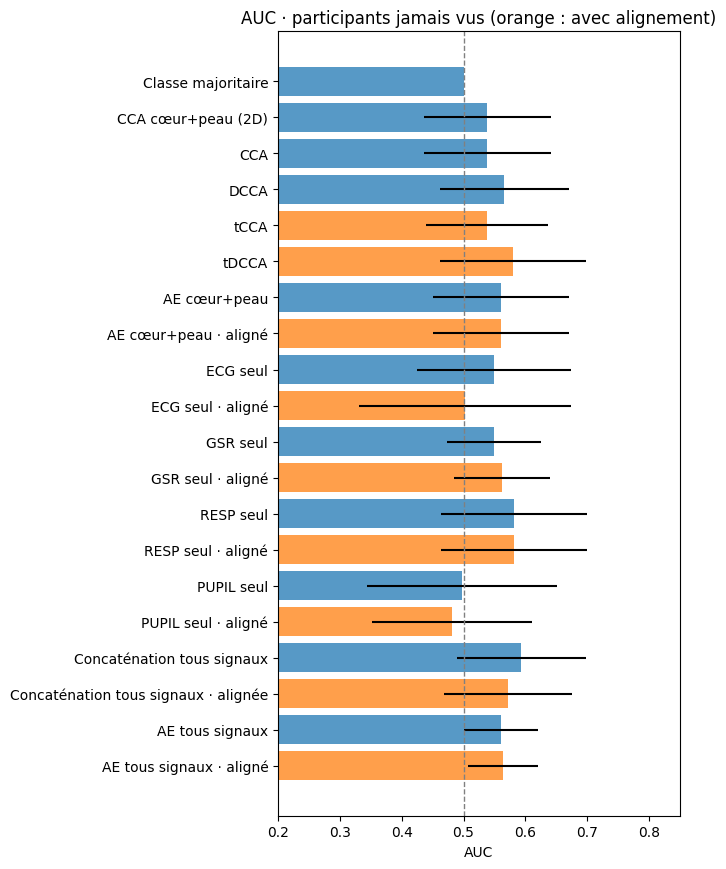

In [14]:
def cca_code(f, rows):
    u, v = cca_transform(f["model"], XL[REF][0][rows], XL[MOVED][f["lag"]][rows])
    return (u / f["u_sd"] + v / f["v_sd"]) / 2


scores_align = []
for k, (train, test) in enumerate(folds):
    tr, te = train[labelled[train]], test[labelled[test]]
    if len(te) < 5 or len(set(target[te])) < 2 or len(set(target[tr])) < 2:
        continue
    y_tr, y_te = target[tr], target[te]
    lags = signal_lags[k]
    versions = {name: (cca_code(cca_fits[k][name], tr), cca_code(cca_fits[k][name], te)) for name in CCA_METHODS}
    for m in USED_MODALITIES:
        versions[f"{m} seul · aligné"] = (XL[m][lags[m]][tr], XL[m][lags[m]][te])
    versions["Concaténation tous signaux · alignée"] = tuple(
        np.column_stack([XL[m][lags[m]][rows] for m in USED_MODALITIES]) for rows in (tr, te))
    for name, (f_tr, f_te) in versions.items():
        ba, auc = probe(f_tr, f_te, y_tr, y_te)
        scores_align.append({"participant": groups[test][0], "version": name, "balanced accuracy": ba, "AUC": auc})
    for name, (models, arrays) in ae_aligned[k].items():
        per_seed = [probe(ae_shared(m, arrays, tr), ae_shared(m, arrays, te), y_tr, y_te) for m in models]
        scores_align.append({"participant": groups[test][0], "version": name,
                             "balanced accuracy": np.mean([s[0] for s in per_seed]),
                             "AUC": np.mean([s[1] for s in per_seed])})

scores_all = pd.concat([scores, pd.DataFrame(scores_align)], ignore_index=True)
order_align = (["Classe majoritaire", "CCA cœur+peau (2D)"] + CCA_METHODS
               + ["AE cœur+peau", "AE cœur+peau · aligné"]
               + [v for m in USED_MODALITIES for v in (f"{m} seul", f"{m} seul · aligné")]
               + ["Concaténation tous signaux", "Concaténation tous signaux · alignée",
                  "AE tous signaux", "AE tous signaux · aligné"])
summary_align = scores_all.groupby("version")[["balanced accuracy", "AUC"]].agg(["mean", "std"]).reindex(order_align)
display(summary_align.round(3))

# Le tableau 2 × 2 de la présentation : méthode × alignement, pour les deux mesures.
pairs_2x2 = {"CCA cœur+peau": ("CCA", "tCCA"), "DCCA cœur+peau": ("DCCA", "tDCCA"),
             "AE cœur+peau": ("AE cœur+peau", "AE cœur+peau · aligné")}
table_2x2 = pd.DataFrame({(metric, col): [summary_align.loc[pair[i], (metric, "mean")] for pair in pairs_2x2.values()]
                          for metric in ["AUC", "balanced accuracy"]
                          for i, col in enumerate(["sans alignement", "avec alignement"])},
                         index=list(pairs_2x2))
display(table_2x2.round(3))

fig, ax = plt.subplots(figsize=(7, 0.38 * len(order_align) + 1.2))
aligned = [("align" in v) or v.startswith("t") for v in order_align]
ax.barh(order_align, summary_align[("AUC", "mean")], xerr=summary_align[("AUC", "std")],
        color=["tab:orange" if a else "tab:blue" for a in aligned], alpha=0.75)
ax.axvline(0.5, color="gray", ls="--", lw=1)
ax.set(xlabel="AUC", xlim=(0.2, 0.85), title="AUC · participants jamais vus (orange : avec alignement)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 9.3 · Comparaisons participant par participant

Même lecture qu'en section 7 : si l'intervalle de confiance contient 0, on ne peut pas conclure. Les comparaisons sont données pour les deux mesures, l'AUC d'abord (mesure principale).

In [15]:
COMPARISONS_ALIGN = ([("tCCA", "CCA"), ("DCCA", "CCA"), ("tDCCA", "CCA"), ("tDCCA", "DCCA"),
                      ("AE cœur+peau · aligné", "AE cœur+peau"), ("AE cœur+peau · aligné", "tDCCA"),
                      ("AE cœur+peau", "CCA"),
                      ("Concaténation tous signaux · alignée", "Concaténation tous signaux"),
                      ("AE tous signaux · aligné", "AE tous signaux")]
                     + [(f"{m} seul · aligné", f"{m} seul") for m in USED_MODALITIES])
for metric in ["AUC", "balanced accuracy"]:
    print(f"\nMesure : {metric}")
    display(paired_table(scores_all, COMPARISONS_ALIGN, metric))


Mesure : AUC


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,tCCA,CCA,8 / 20,-0.001,-0.021,0.020,1.000
1,DCCA,CCA,11 / 20,0.027,-0.011,0.068,0.368
2,tDCCA,CCA,12 / 20,0.042,-0.005,0.090,0.189
3,tDCCA,DCCA,13 / 20,0.014,-0.001,0.029,0.037
4,AE cœur+peau · aligné,AE cœur+peau,0 / 20,0.000,0.000,0.000,NaN
5,AE cœur+peau · aligné,tDCCA,7 / 20,-0.020,-0.063,0.025,0.452
6,AE cœur+peau,CCA,10 / 20,0.022,-0.022,0.067,0.422
7,Concaténation tous signaux · alignée,Concaténation tous signaux,7 / 20,-0.022,-0.063,0.019,0.327
8,AE tous signaux · aligné,AE tous signaux,14 / 20,0.004,-0.022,0.026,0.271
9,ECG seul · aligné,ECG seul,5 / 20,-0.047,-0.116,0.026,0.158



Mesure : balanced accuracy


,A,B,victoires de A,différence moyenne,IC 95 % bas,IC 95 % haut,p (Wilcoxon)
0,tCCA,CCA,5 / 20,-0.013,-0.039,0.013,0.410
1,DCCA,CCA,12 / 20,0.028,-0.010,0.065,0.153
2,tDCCA,CCA,12 / 20,0.017,-0.032,0.065,0.563
3,tDCCA,DCCA,7 / 20,-0.012,-0.049,0.019,0.865
4,AE cœur+peau · aligné,AE cœur+peau,0 / 20,0.000,0.000,0.000,NaN
5,AE cœur+peau · aligné,tDCCA,10 / 20,0.008,-0.031,0.052,0.904
6,AE cœur+peau,CCA,12 / 20,0.025,-0.021,0.072,0.349
7,Concaténation tous signaux · alignée,Concaténation tous signaux,6 / 20,-0.023,-0.058,0.009,0.221
8,AE tous signaux · aligné,AE tous signaux,9 / 20,-0.001,-0.030,0.026,0.469
9,ECG seul · aligné,ECG seul,4 / 20,-0.014,-0.072,0.056,0.463


## 10 · Quels décalages ressortent ? (latence, hypothèse H1)

À gauche, les décalages choisis dans chaque pli (un point par participant testé). À droite, les courbes moyennes des critères de choix en fonction du décalage, sur les participants d'apprentissage.

En dessous, une courbe **descriptive** : l'AUC sur le participant testé pour chaque signal et chaque décalage. Elle sert à **comprendre** où se trouve l'information, **pas à choisir** le décalage (le choisir sur cette courbe serait tricher, car elle utilise le participant testé).

**À comparer avec la physiologie :** peau vers 2 à 4 s, cœur avec un effet tardif possible, pupille sans décalage. Si les décalages choisis varient beaucoup d'un pli à l'autre, l'alignement n'est pas stable avec ces données.

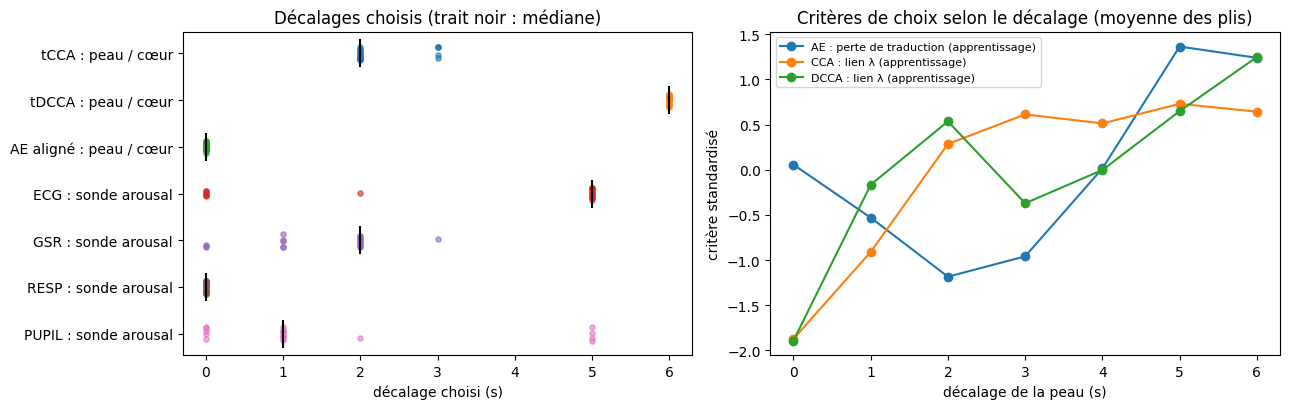

,mean,50%,min,max
choix,,,,
AE aligné : peau / cœur,0.00,0.0,0.0,0.0
ECG : sonde arousal,3.35,5.0,0.0,5.0
GSR : sonde arousal,1.50,2.0,0.0,3.0
PUPIL : sonde arousal,1.60,1.0,0.0,5.0
RESP : sonde arousal,0.00,0.0,0.0,0.0
tCCA : peau / cœur,2.25,2.0,2.0,3.0
tDCCA : peau / cœur,6.00,6.0,6.0,6.0


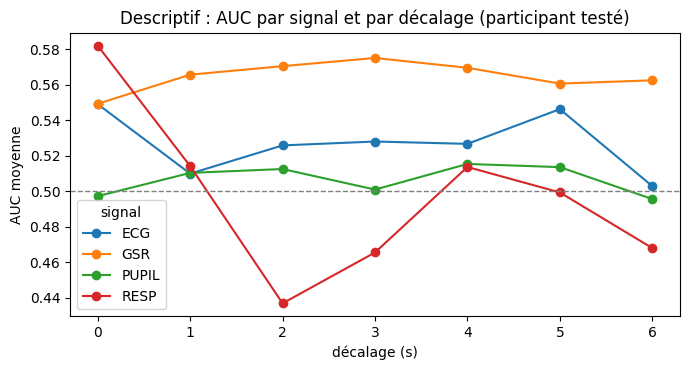

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
choices = list(chosen_lags["choix"].unique())
for i, c in enumerate(choices):
    vals = chosen_lags.loc[chosen_lags["choix"] == c, "décalage (s)"].to_numpy()
    jitter = np.random.default_rng(i).uniform(-0.15, 0.15, len(vals))
    axes[0].scatter(vals, i + jitter, s=14, alpha=0.6)
    axes[0].scatter(np.median(vals), i, marker="|", s=400, color="black")
axes[0].set(yticks=range(len(choices)), yticklabels=choices, xlabel="décalage choisi (s)",
            title="Décalages choisis (trait noir : médiane)")
axes[0].invert_yaxis()

curves = lag_curves.groupby(["critère", "décalage (s)"]).valeur.mean().unstack(0)
for name in curves:
    col = curves[name]
    axes[1].plot(curves.index, (col - col.mean()) / (col.std() if col.std() > 0 else 1), marker="o", label=name)
axes[1].set(xlabel="décalage de la peau (s)", ylabel="critère standardisé",
            title="Critères de choix selon le décalage (moyenne des plis)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

display(chosen_lags.groupby("choix")["décalage (s)"].describe()[["mean", "50%", "min", "max"]].round(2))

# Courbe descriptive : AUC sur le participant testé, par signal et par décalage.
descr = []
for k, (train, test) in enumerate(folds):
    tr, te = train[labelled[train]], test[labelled[test]]
    if len(te) < 5 or len(set(target[te])) < 2 or len(set(target[tr])) < 2:
        continue
    for m in USED_MODALITIES:
        for lag in LAGS_S:
            descr.append({"signal": m, "décalage (s)": lag,
                          "AUC": probe(XL[m][lag][tr], XL[m][lag][te], target[tr], target[te])[1]})
descr = pd.DataFrame(descr).groupby(["décalage (s)", "signal"]).AUC.mean().unstack()
ax = descr.plot(marker="o", figsize=(7, 3.8), title="Descriptif : AUC par signal et par décalage (participant testé)")
ax.axhline(0.5, color="gray", ls="--", lw=1)
ax.set(ylabel="AUC moyenne")
plt.tight_layout()
plt.show()

## 11 · Comment lire les résultats

**Les questions auxquelles ce notebook répond :**

1. **Une version fait-elle mieux que le hasard ?** Sa note moyenne dépasse-t-elle 0,50, avec un écart-type qui ne la fait pas retomber dessous pour la plupart des participants ?
2. **L'autoencodeur fait-il mieux que la CCA ?** Première ligne de la section 7.
3. **Ajouter la respiration et la pupille aide-t-il ?** « AE tous signaux » contre « AE cœur+peau », et « Concaténation tous signaux » contre le meilleur signal seul.
4. **Quelle règle de l'autoencodeur compte ?** Les trois lignes d'ablation : si « reconstruction seule » fait aussi bien que l'autoencodeur complet, l'avantage vient de l'information propre à chaque signal, pas du lien entre eux.
5. **Le cœur et la peau sont-ils liés ?** Section 5 : combien de participants dépassent la zone du hasard.
6. **Aligner aide-t-il ?** Le tableau 2 × 2 de la section 9.2 et les lignes « tCCA vs CCA », « AE aligné vs AE » de la section 9.3. Section 9.1 pour le lien cœur–peau.
7. **Utiliser les notes (DCCA) aide-t-il ?** « DCCA vs CCA » et « tDCCA vs DCCA ».
8. **Quels délais ressortent ?** Section 10 : décalages choisis et leur stabilité d'un pli à l'autre.

**Repère :** dans Hou et al. 2024, sur des personnes jamais vues, la tDCCA ne gagne qu'environ un point d'accuracy sur la CCA (par exemple 0,602 → 0,609 avec un SVM, écart-type ±0,088). Un petit gain, ou pas de gain, est donc un résultat normal ; l'important est de le mesurer honnêtement.

**À noter dans le rapport :** participants sélectionnés et retenus, nombre d'essais complets et notés (et combien sont perdus à cause des décalages), cohortes, signaux utilisés, réglages (`EPOCHS`, `SEEDS`, `LATENT_DIM`, `LAGS_S`), et les limites.

**Limites connues :**

- La standardisation et la cible utilisent toutes les vidéos du participant testé (sans leurs notes) : ce n'est pas un prédicteur utilisable dès la première vidéo d'une nouvelle personne.
- La pupille réagit d'abord à la luminosité des vidéos, inconnue ici.
- Les fenêtres décalées peuvent dépasser la fin de la vidéo : on mesure alors aussi la fin de la réaction, et parfois le début de l'écran de notation.
- Choisir un décalage, c'est ajouter un réglage : s'il n'apporte rien de net, il peut faire légèrement moins bien que le décalage 0 (d'où la règle `LAG_TOL`).
- Le décalage est un seul nombre par pli, le même pour tous les participants et toutes les vidéos ; en réalité il varie sans doute d'une personne à l'autre.
- Avec deux classes, la DCCA n'a qu'**une** dimension vraiment utile (les moyennes des deux classes sont presque opposées) ; sa 2e dimension est peu informative.
- Les mêmes vidéos reviennent chez plusieurs participants : un modèle peut en partie reconnaître la vidéo plutôt que la réaction.
- Les réglages de l'autoencodeur sont fixés à l'avance, sans optimisation, pour ne pas tricher sans le vouloir.

## 12 · La peau décalée du délai mesuré (latence cœur → peau ≈ 2,5 s)

L'étude de latence (notebook v6, outil de Hugo) montre que la peau réagit environ 2,5 s après le cœur. Ici, le décalage de la peau est **fixé à l'avance** à 2 ou 3 s, sans le chercher : on regarde simplement la peau « au bon moment ». Les autres signaux restent sans décalage. Même sonde et même protocole qu'avant (un participant jamais vu à chaque fois).

**Lecture :** si « 2 s » ou « 3 s » gagne chez la plupart des participants, avec un p < 0,05, le délai mesuré améliore la prédiction de l'arousal.

In [17]:
# La peau décalée d'un délai FIXÉ à l'avance (résultat de la latence : ~2,5 s), sans recherche.
rows_lag = []
for train, test in folds:
    tr, te = train[labelled[train]], test[labelled[test]]
    if len(te) < 5 or len(set(target[te])) < 2:
        continue
    for lag in [0, 2, 3]:
        F = np.column_stack([XL["ECG"][0], XL["GSR"][lag], XL["RESP"][0], XL["PUPIL"][0]])
        p = LogisticRegression(class_weight="balanced", max_iter=2000).fit(F[tr], target[tr]).predict_proba(F[te])[:, 1]
        rows_lag.append({"participant": groups[test][0], "peau décalée de": f"{lag} s",
                         "AUC": roc_auc_score(target[te], p),
                         "balanced accuracy": balanced_accuracy_score(target[te], p > 0.5)})
res_lag = pd.DataFrame(rows_lag)
display(res_lag.groupby("peau décalée de")[["AUC", "balanced accuracy"]].agg(["mean", "std"]).round(3))
for metric in ["AUC", "balanced accuracy"]:
    w = res_lag.pivot(index="participant", columns="peau décalée de", values=metric)
    for lag in ["2 s", "3 s"]:
        d = w[lag] - w["0 s"]
        print(f"{metric} · peau décalée de {lag} vs sans décalage : {d.mean():+.3f}, gagne chez {(d > 0).sum()} / {len(d)}, "
              f"p = {wilcoxon(d).pvalue:.3f}")

AUC        balanced accuracy       
                  mean    std              mean    std
peau décalée de                                       
0 s              0.594  0.104             0.559  0.082
2 s              0.601  0.101             0.570  0.091
3 s              0.597  0.109             0.566  0.091

AUC · peau décalée de 2 s vs sans décalage : +0.008, gagne chez 12 / 20, p = 0.420
AUC · peau décalée de 3 s vs sans décalage : +0.003, gagne chez 7 / 20, p = 0.906
balanced accuracy · peau décalée de 2 s vs sans décalage : +0.012, gagne chez 5 / 20, p = 0.260
balanced accuracy · peau décalée de 3 s vs sans décalage : +0.007, gagne chez 7 / 20, p = 0.373
